# Case Study Data Analysis and Data Visualization

## Ecommerce Sales Data

In [55]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [56]:
df = pd.read_csv('Ecomm_Sales.csv')

In [57]:
df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


**Ques. Generate the summary of the dataset and find missing values (if any).**

In [60]:
print('The Summary of Sales Dataset is:\n')
df.info()

The Summary of Sales Dataset is:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


In [61]:
df.isna().sum()

order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64

**Observation:**
- No missing values are found in the dataset.

**Ques. Check if there are any duplicates or not and drop all the duplicate rows.**

In [62]:
df.duplicated().sum()                # to check duplicate rows, we use duplicated() method

0

**Observation:**
- No duplicates are observed.

**Ques. Find-**
1. **Number of rows and columns**
2. **Column names**
3. **Data types**

In [63]:
print('The number of rows and columns are:')
df.shape

The number of rows and columns are:


(5000, 12)

In [65]:
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

Rows: 5000
Columns: 12


In [66]:
print('Column Names:')
df.columns

Column Names:


Index(['order_id', 'order_date', 'customer_id', 'product_category', 'region',
       'quantity', 'unit_price', 'discount', 'payment_method', 'delivery_days',
       'customer_rating', 'revenue'],
      dtype='object')

In [67]:
print('The Data types are:')
df.dtypes

The Data types are:


order_id              int64
order_date           object
customer_id           int64
product_category     object
region               object
quantity              int64
unit_price          float64
discount            float64
payment_method       object
delivery_days         int64
customer_rating     float64
revenue             float64
dtype: object

**Ques. Convert order date column into a date time format column.**

In [68]:
df['order_date'] = pd.to_datetime(df['order_date'])

In [70]:
df.dtypes

order_id                     int64
order_date          datetime64[ns]
customer_id                  int64
product_category            object
region                      object
quantity                     int64
unit_price                 float64
discount                   float64
payment_method              object
delivery_days                int64
customer_rating            float64
revenue                    float64
dtype: object

**Ques. Create a new column Month and fill it with month names.**

In [73]:
df['month'] = df['order_date'].dt.strftime('%B')

In [74]:
df.head(3)

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue,month
0,10001,2022-01-01,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20,January
1,10002,2022-01-02,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10,January
2,10003,2022-01-03,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35,January


**Ques. Generate descriptive statistics for all numerical columns.**

In [75]:
df.describe()

,order_id,order_date,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,2028-11-04 12:00:00,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
min,10001.000000,2022-01-01 00:00:00,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,2025-06-03 18:00:00,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,2028-11-04 12:00:00,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,2032-04-07 06:00:00,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,2035-09-09 00:00:00,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000
std,1443.520003,NaN,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219


**Ques. How many unique product categories and regions are present?**

In [78]:
print(f'Total Unique Product Categories: {df["product_category"].nunique()}\n')
print(f'Types of Product Categories: {df["product_category"].unique()}')

Total Unique Product Categories: 4

Types of Product Categories: ['Beauty' 'Clothing' 'Electronics' 'Home']


In [79]:
print(f'Total Unique Regions: {df["region"].nunique()}\n')
print(f'Types of Regions: {df["region"].unique()}')

Total Unique Regions: 4

Types of Regions: ['South' 'East' 'West' 'North']


### Univariate Analysis
##### Analysis of a single variable

**Ques. What is the distribution of revenue?**

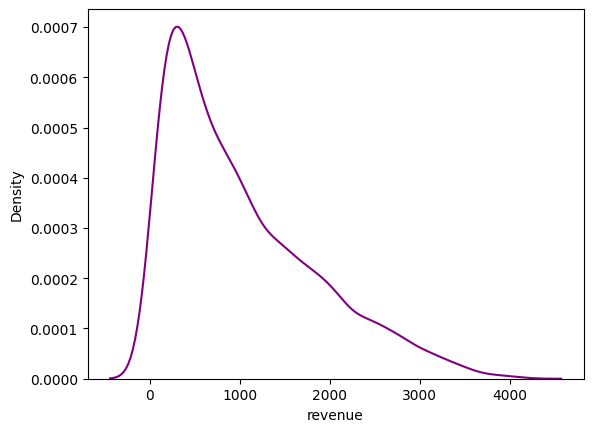

In [80]:
sns.kdeplot(x='revenue', data=df, color='purple')
plt.show()

**Ques. Are there any outliers in revenue?**<br>
**Ans: Yes**

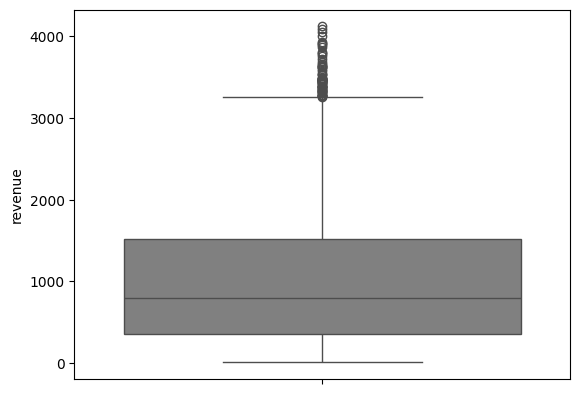

In [24]:
sns.boxplot(y='revenue', data=df, color='grey')
plt.show()

**Ques. What is the average quantity ordered?**

In [81]:
print(f"Average Quantity: {df['quantity'].mean()}")

Average Quantity: 4.0448


**Ques. Which product category has the highest number of orders? Draw its Visualization too.**

In [82]:
df['product_category'].value_counts()

product_category
Electronics    1777
Clothing       1531
Home            969
Beauty          723
Name: count, dtype: int64

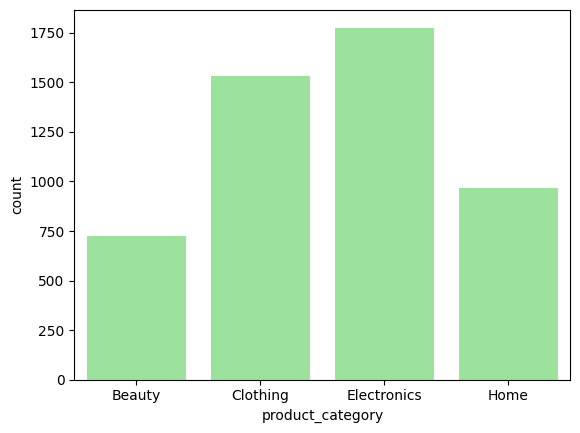

In [83]:
sns.countplot(x='product_category', data=df, color='lightgreen')
plt.show()

**Ques. What percentage of orders come from each region?**

In [87]:
df['region'].value_counts()

region
West     1289
North    1276
East     1227
South    1208
Name: count, dtype: int64

In [88]:
regions = df['region'].value_counts().index
values = df['region'].value_counts().values

In [89]:
regions

Index(['West', 'North', 'East', 'South'], dtype='object', name='region')

In [90]:
values

array([1289, 1276, 1227, 1208], dtype=int64)

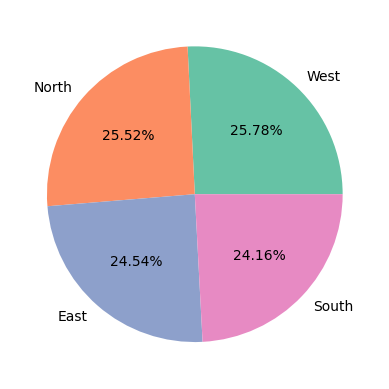

In [91]:
plt.pie(values, labels=regions, autopct='%0.2f%%',
        colors=sns.color_palette('Set2'))
plt.show()

**Ques. Which payment method is most popular?**

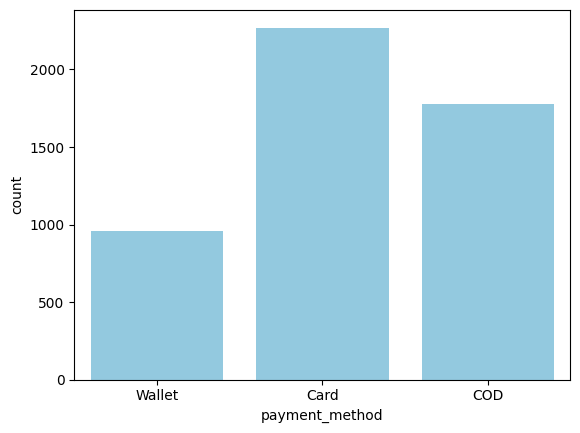

In [92]:
sns.countplot(x='payment_method', data=df, color='skyblue')
plt.show()

### Bivariate Analysis

**Ques. Which product category generates the highest total revenue? Display it in millions.**

In [130]:
# as_index=False ---> creating a dataframe by keeping index values as column
category_revenue = df.groupby('product_category', as_index=False)['revenue'].sum()

In [131]:
category_revenue

,product_category,revenue
0,Beauty,765860.88
1,Clothing,1531931.72
2,Electronics,1829899.22
3,Home,982083.92


In [132]:
category_revenue['revenue (in millions)'] = category_revenue['revenue']/1000000

In [133]:
category_revenue

,product_category,revenue,revenue (in millions)
0,Beauty,765860.88,0.765861
1,Clothing,1531931.72,1.531932
2,Electronics,1829899.22,1.829899
3,Home,982083.92,0.982084


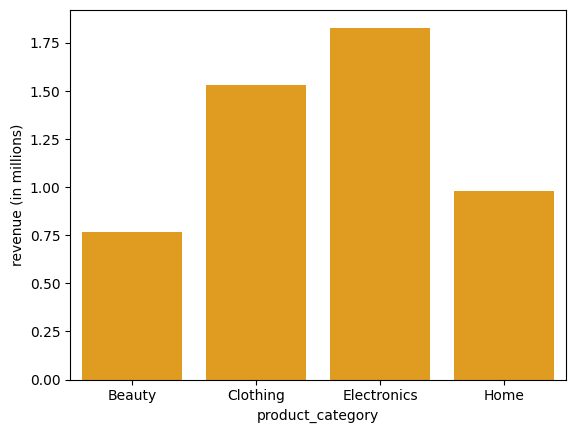

In [134]:
sns.barplot(x='product_category', y='revenue (in millions)', data=category_revenue, color='orange')
plt.show()

**Ques. Does increasing discount increase revenue?**

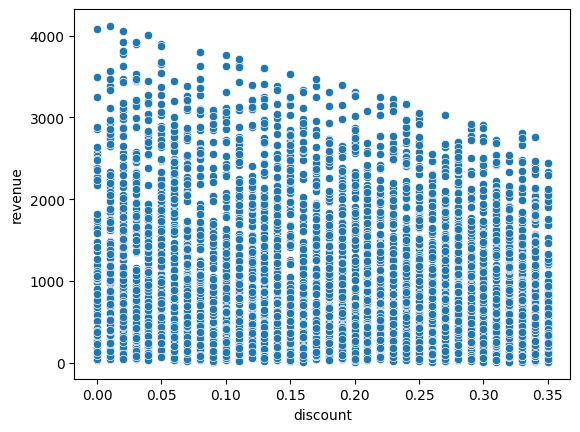

In [135]:
sns.scatterplot(x='discount', y='revenue', data=df)
plt.show()

**Using Lineplot**

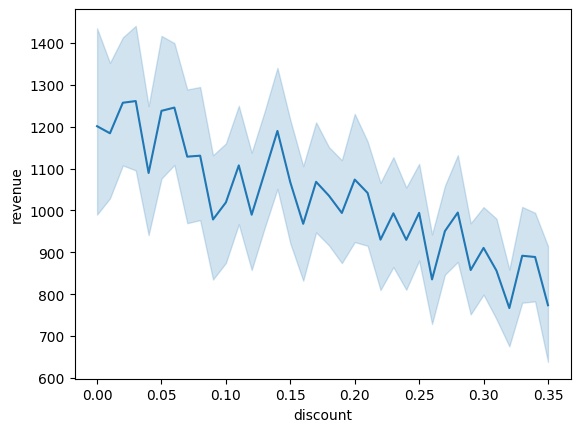

In [137]:
sns.lineplot(x='discount', y='revenue', data=df)
plt.show()

**Observation:**
- Revenue tends to decrease as discount increases.

**Ques. Compare the revenue distribution of different categories**

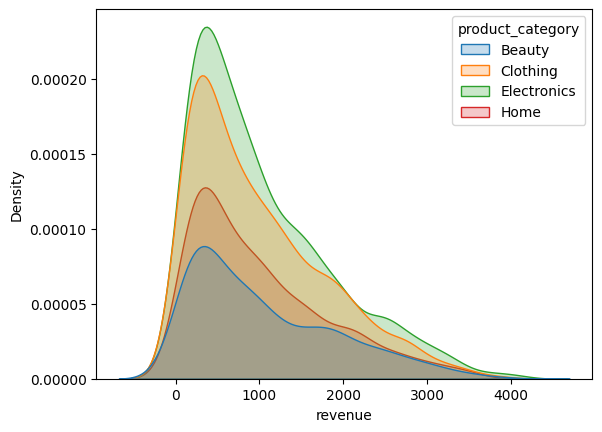

In [141]:
# fill=True ---> It fills the distribution
sns.kdeplot(x='revenue', data=df, hue='product_category', fill=True)
plt.show()

**Ques. Which month generated offers the highest sales?**

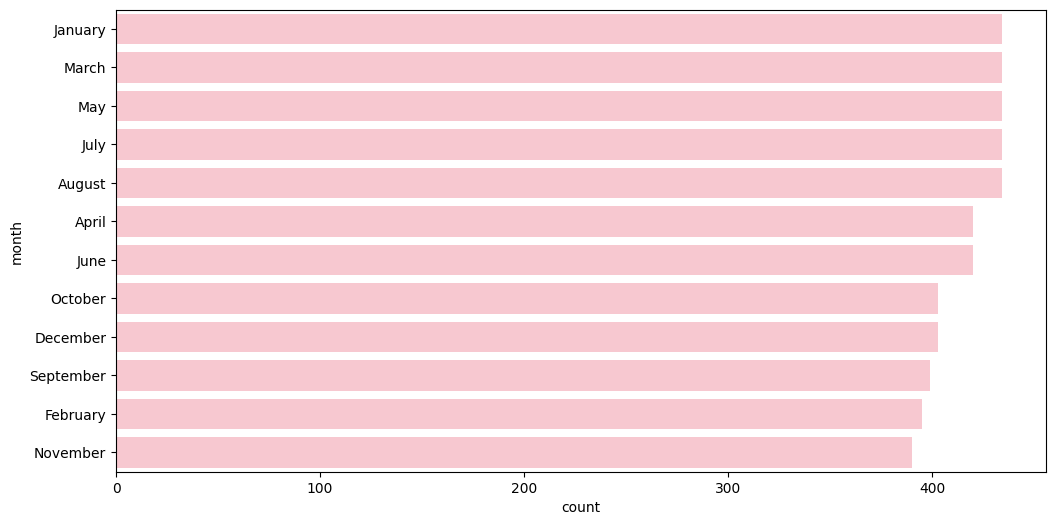

In [151]:
plt.figure(figsize=(12,6))
sns.countplot(y='month', data=df, color='pink',
              order=df['month'].value_counts().index)     # order ---> sorts the data in dec. order
plt.show()

**Ques. Which month generated the highest revenue?**

In [159]:
month_revenue = df.groupby('month', as_index=False)['revenue'].sum()
month_revenue

,month,revenue
0,April,398715.16
1,August,460874.78
2,December,400686.16
3,February,413890.24
4,January,426374.92
5,July,440570.72
6,June,442941.58
7,March,425050.52
8,May,479772.55
9,November,410657.88


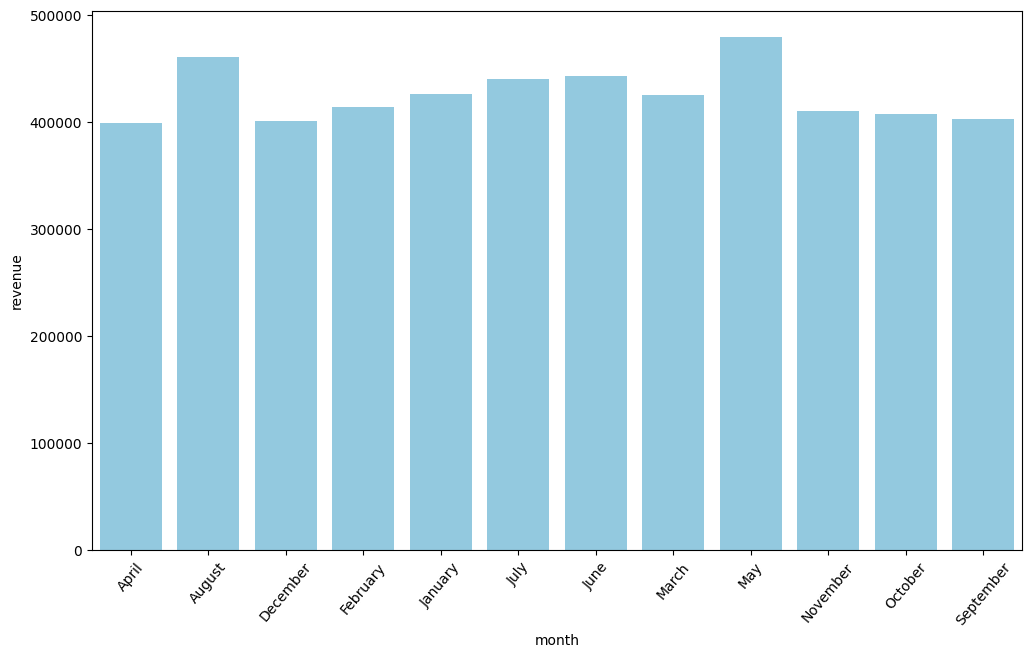

In [163]:
plt.figure(figsize=(12,7))
sns.barplot(x='month', y='revenue', data=month_revenue, color='skyblue')
plt.xticks(rotation=50)
plt.show()

**Ques. Find the relationship between unit_price and discount.**

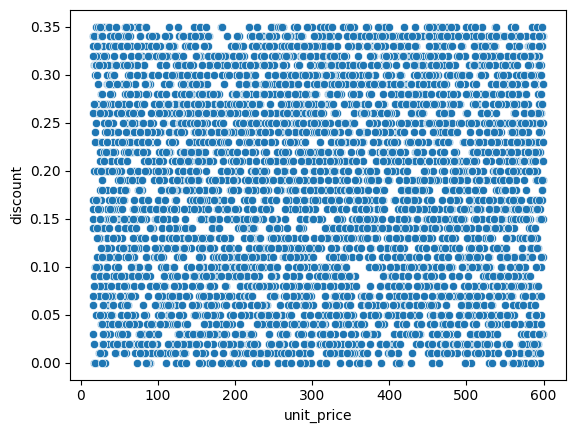

In [170]:
sns.scatterplot(x='unit_price', y='discount', data=df)
plt.show()

**Observation:**
- No correlation is observed in between unit price and discount.

### Multivariate Analysis

**Ques. Which region sells the highest quantity in each category?**

In [212]:
prod_quantity = df.groupby(['product_category','region'], as_index=False)['quantity'].sum()
prod_quantity.head()

,product_category,region,quantity
0,Beauty,East,649
1,Beauty,North,787
2,Beauty,South,745
3,Beauty,West,814
4,Clothing,East,1618


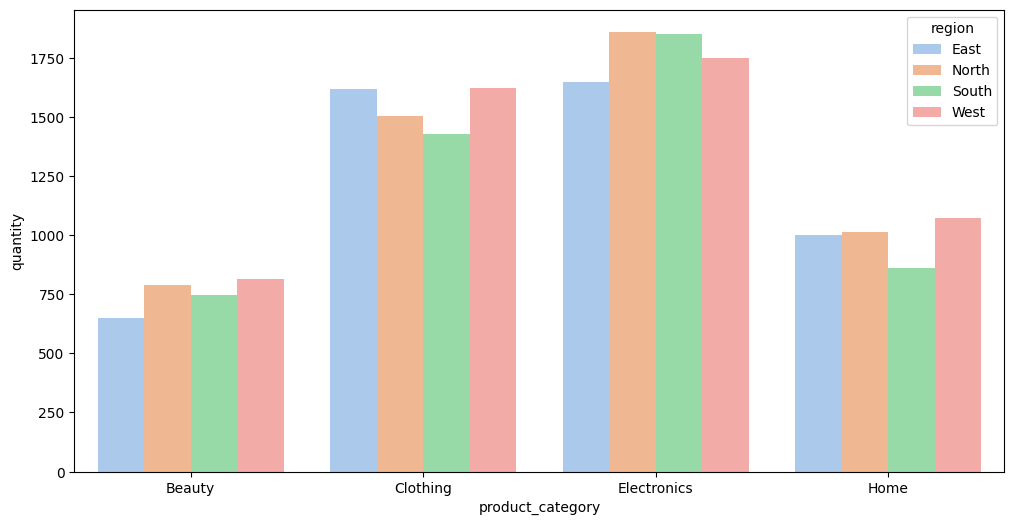

In [253]:
plt.figure(figsize=(12,6))
sns.barplot(x='product_category', y='quantity', data=prod_quantity, hue='region', palette='pastel')
plt.show()

**Ques. Compare the distribution of revenue for different regions.**

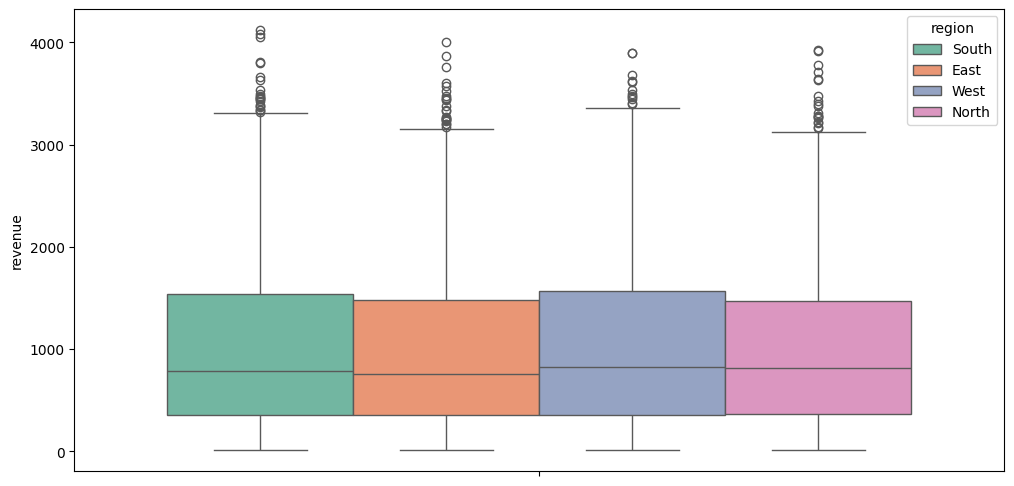

In [251]:
plt.figure(figsize=(12,6))
sns.boxplot(y='revenue', data=df, hue='region', palette='Set2')
plt.show()

**Ques. Find the correlation between all numeric columns.**

In [241]:
df_numeric = df[['quantity','unit_price','discount','delivery_days','customer_rating','revenue']]
df_numeric.head()

,quantity,unit_price,discount,delivery_days,customer_rating,revenue
0,7,373.65,0.28,10,4.7,1883.20
1,7,47.74,0.09,6,3.9,304.10
2,3,311.28,0.31,6,2.5,644.35
3,5,524.47,0.02,6,1.6,2569.90
4,5,139.87,0.33,4,4.9,468.56


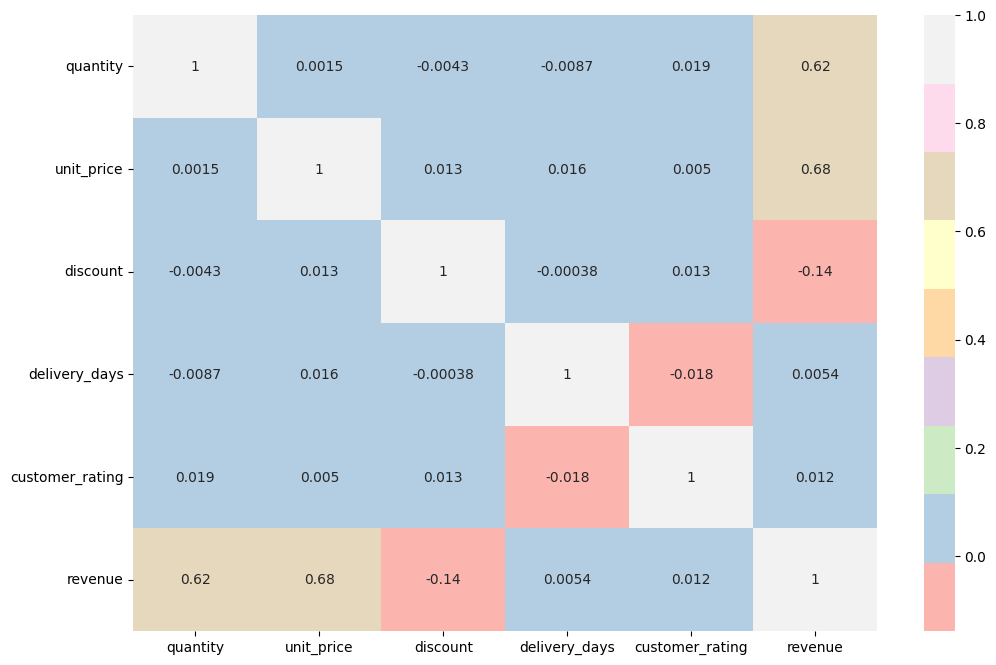

In [248]:
plt.figure(figsize=(12,8))
sns.heatmap(df_numeric.corr(), annot=True, cmap='Pastel1')
plt.show()

**Ques. Draw correlation distribution using pairplot.**

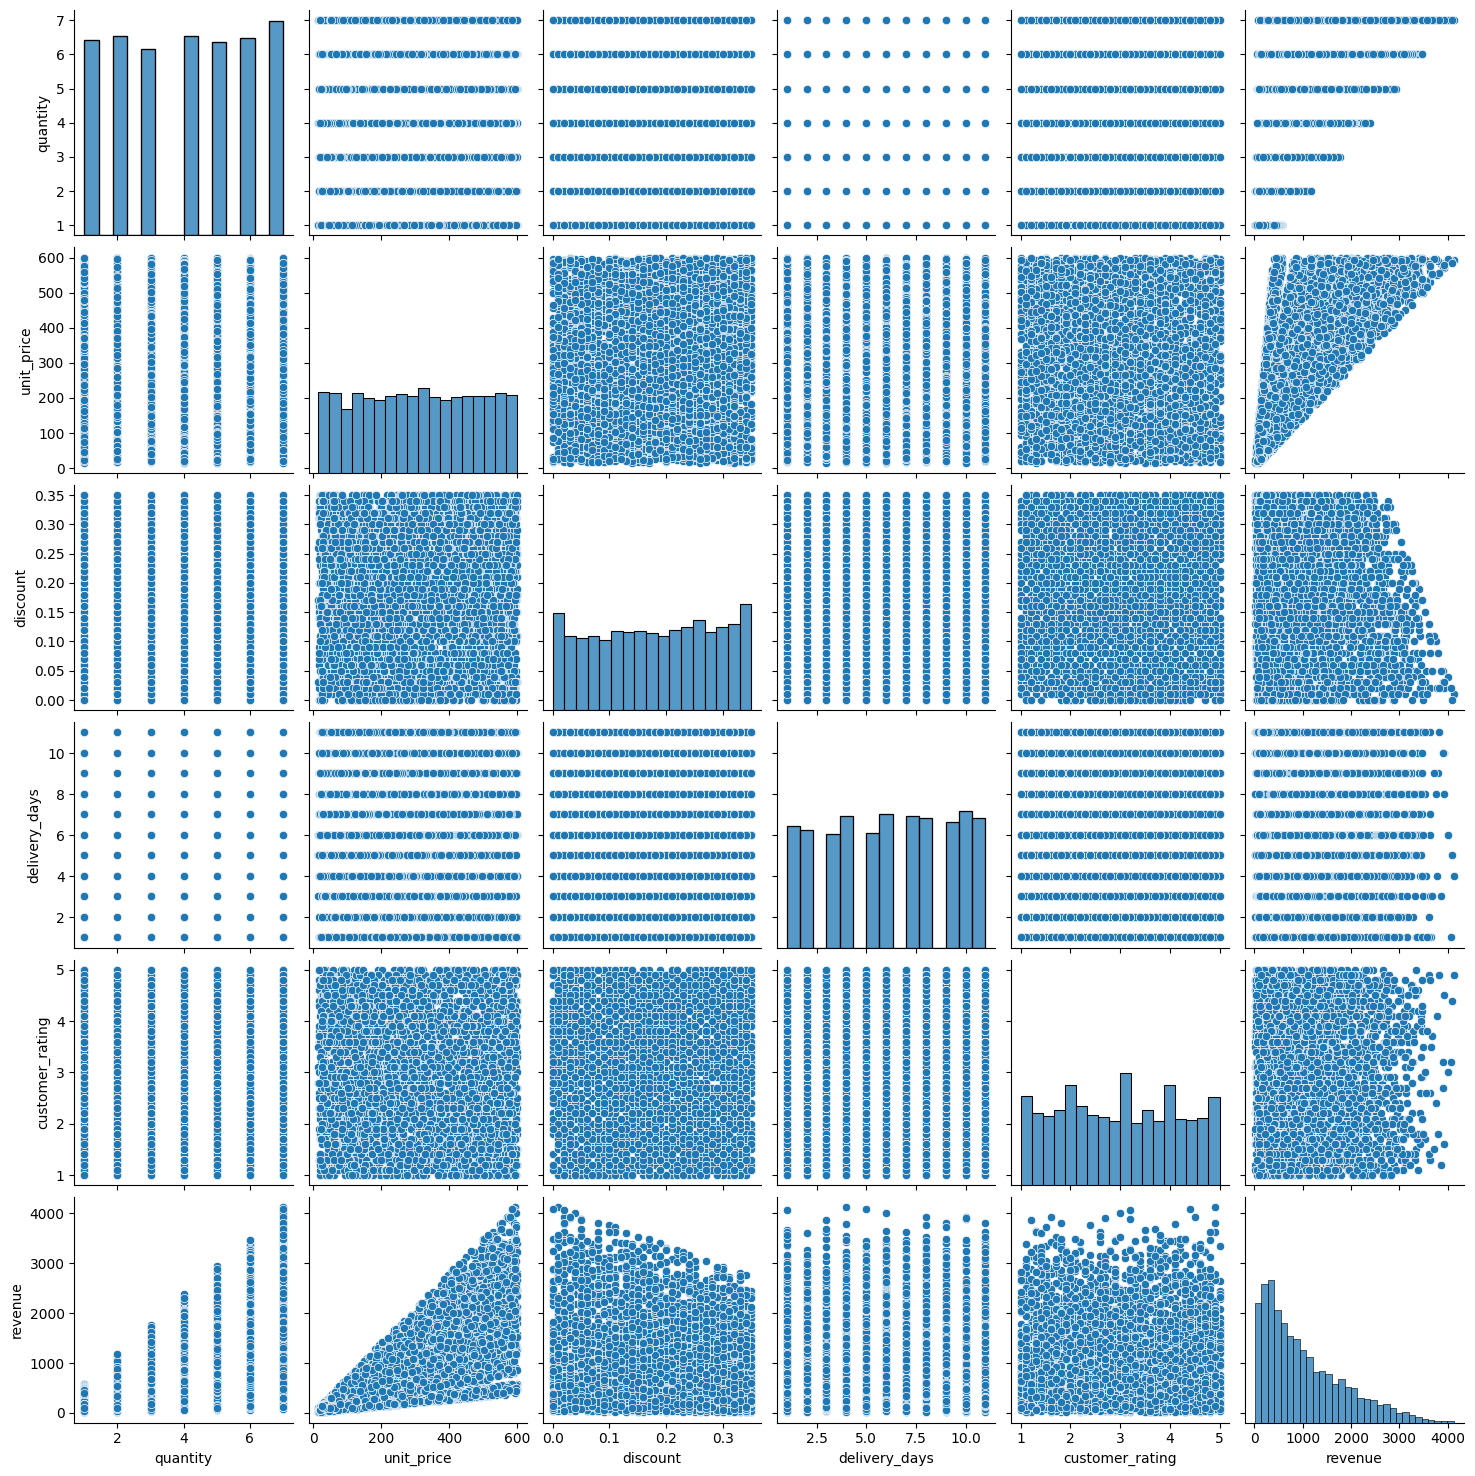

In [255]:
sns.pairplot(df_numeric)
plt.show()

**Correlation of continuous variables**

In [256]:
df2 = df[['unit_price','discount','revenue']]
df2.head(2)

,unit_price,discount,revenue
0,373.65,0.28,1883.2
1,47.74,0.09,304.1


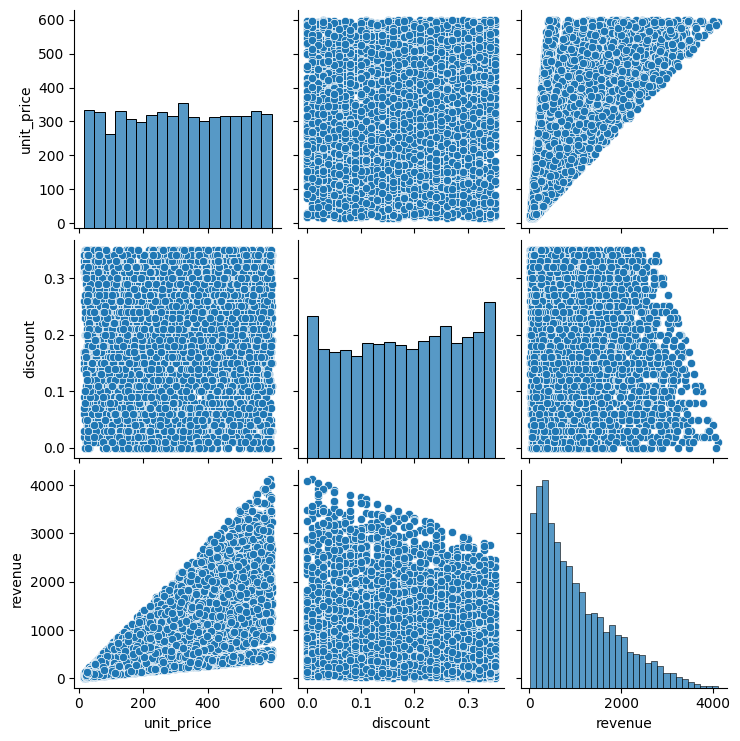

In [257]:
sns.pairplot(df2)
plt.show()

**Ques. Create a dashboard and save the figure using multiple plots.**

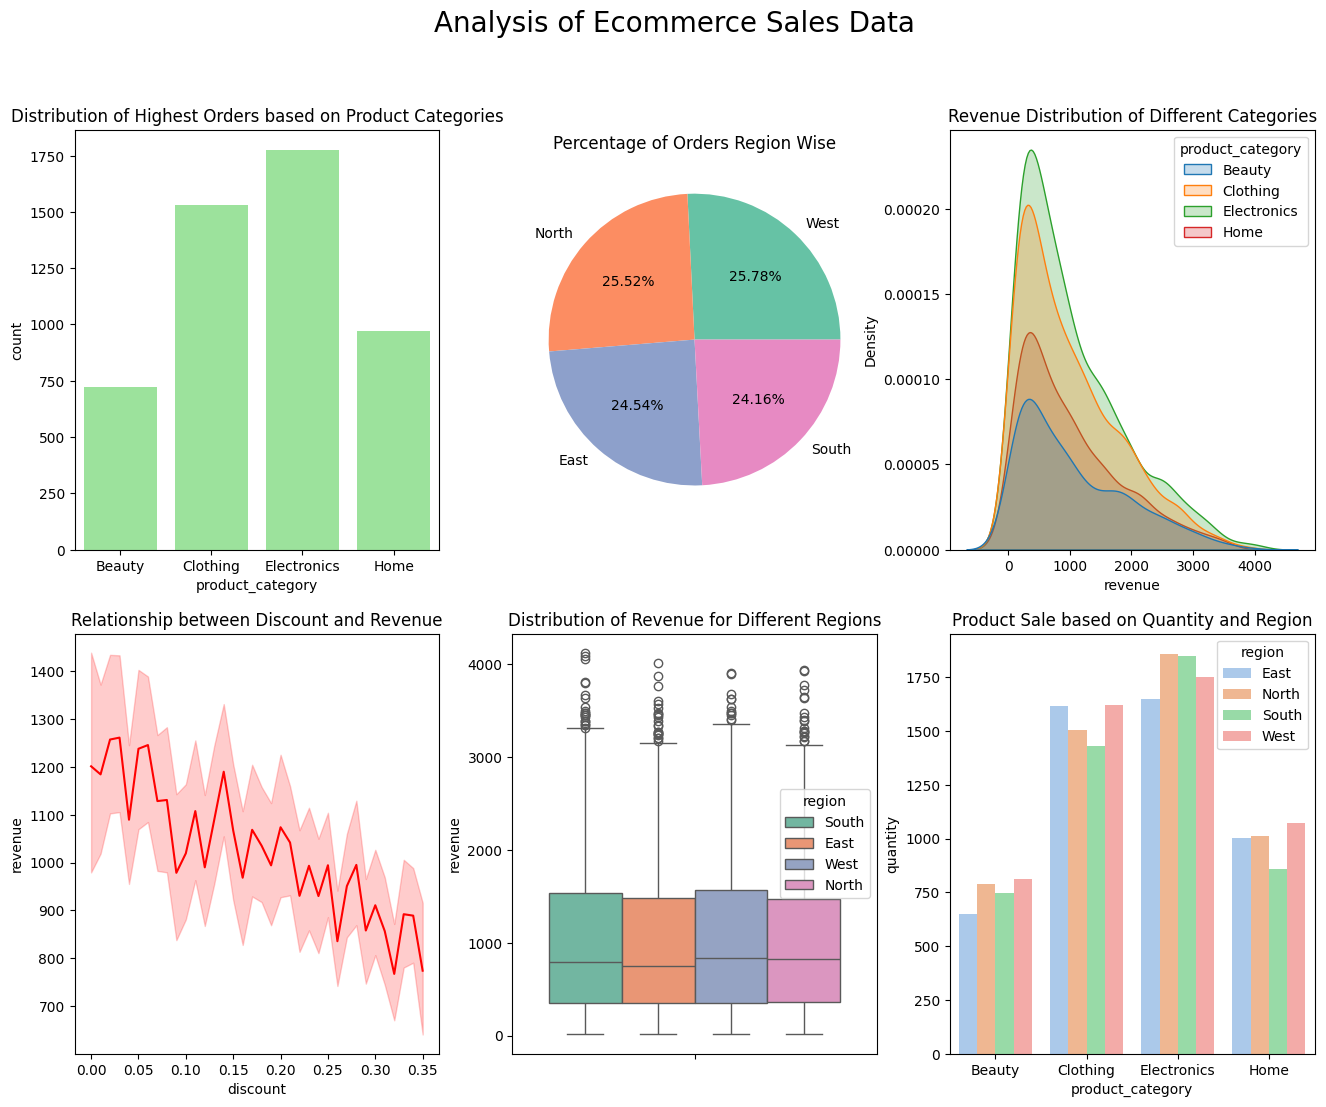

In [260]:
plt.figure(figsize=(16,12)).suptitle("Analysis of Ecommerce Sales Data", fontsize=20)

plt.subplot(2,3,1)
sns.countplot(x='product_category', data=df, color='lightgreen')
plt.title('Distribution of Highest Orders based on Product Categories')

plt.subplot(2,3,2)
plt.pie(values, labels=regions, autopct='%0.2f%%', colors=sns.color_palette('Set2'))
plt.title('Percentage of Orders Region Wise')

plt.subplot(2,3,3)
sns.kdeplot(x='revenue', data=df, hue='product_category', fill=True)
plt.title('Revenue Distribution of Different Categories')

plt.subplot(2,3,4)
sns.lineplot(x='discount', y='revenue', data=df, color='red')
plt.title('Relationship between Discount and Revenue')

plt.subplot(2,3,5)
sns.boxplot(y='revenue', data=df, hue='region', palette='Set2')
plt.title('Distribution of Revenue for Different Regions')

plt.subplot(2,3,6)
sns.barplot(x='product_category', y='quantity', data=prod_quantity, hue='region', palette='pastel')
plt.title('Product Sale based on Quantity and Region')

plt.savefig('Ecomm Sales Dashboard')
plt.show()